# SPDC in the photon-number (Fock) basis

### Independent sparse Crank–Nicolson reference for the MPS presentation, $\alpha=5$

This notebook constructs the full Hermitian SPDC Hamiltonian in the Fock basis, evolves the state with sparse Crank–Nicolson linear solves and saves a `.npz` reference for the main MPS notebook. No MPS evolution is performed here.

## 1. Degenerate SPDC Hamiltonian

$$\hat H_{\mathrm{SPDC}}=i\hbar\chi\left(\hat a^\dagger\hat b^2-\hat a(\hat b^\dagger)^2\right),\qquad \hbar=1.$$

With $a|n\rangle=\sqrt{n}|n-1\rangle$, finite Fock cutoffs $n_{\mathrm{pump}}$ and $n_{\mathrm{signal}}$, the Hamiltonian is constructed from sparse creation and annihilation matrices. The physical pump and signal are treated **quantum-mechanically**.

### Imports

In [1]:
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.sparse import diags, eye, kron
from scipy.sparse.linalg import splu
from scipy.special import gammaln

## 2. Parameters

In [2]:
n_pump = 80                      # Fock cutoff: pump
n_signal = 160                   # Fock cutoff: signal
alpha = 5.0
chi = 0.5

t_general = 1.0
steps_number = 200
delta_t = t_general/steps_number

print('Fock dimensions:', n_pump, 'x', n_signal)
print('Method: Crank-Nicolson | steps:', steps_number, '| dt:', delta_t)

Fock dimensions: 80 x 160
Method: Crank-Nicolson | steps: 200 | dt: 0.005


## 3. Sparse SPDC Hamiltonian

The terms $a^\dagger\otimes b^2$ and $a\otimes(b^\dagger)^2$ are constructed directly with sparse Kronecker products. The Fock cutoffs must be large enough that their upper edges remain unoccupied.

In [3]:
annihilate_pump = diags(np.sqrt(np.arange(1, n_pump)), 1,
                         shape=(n_pump, n_pump), dtype=np.complex128, format='csc')
annihilate_signal = diags(np.sqrt(np.arange(1, n_signal)), 1,
                           shape=(n_signal, n_signal), dtype=np.complex128, format='csc')
create_pump = annihilate_pump.getH()
create_signal = annihilate_signal.getH()

hamiltonian_part_1 = kron(create_pump, annihilate_signal@annihilate_signal, format='csc')
hamiltonian_part_2 = kron(annihilate_pump, create_signal@create_signal, format='csc')
full_hamiltonian = 1j*chi*(hamiltonian_part_1-hamiltonian_part_2)

print('Matrix size:', full_hamiltonian.shape)
print('Nonzero Hamiltonian elements:', full_hamiltonian.nnz)

Matrix size: (12800, 12800)
Nonzero Hamiltonian elements: 24964


## 4. Crank–Nicolson evolution operators

For the full physical Hamiltonian $\hat H$,

$$\left(I+\frac{i\Delta t}{2}\hat H\right)\psi_{k+1}=\left(I-\frac{i\Delta t}{2}\hat H\right)\psi_k.$$

The sparse left-hand matrix is LU-factorized **once** and reused for all time steps.

In [4]:
identity_csr = eye(n_pump*n_signal, dtype=np.complex128, format='csc')
evolution_operator_csr = identity_csr + 0.5j*delta_t*full_hamiltonian
right_part_operator = identity_csr - 0.5j*delta_t*full_hamiltonian

print('System matrix sparsity:', evolution_operator_csr.nnz/evolution_operator_csr.shape[0]**2)

System matrix sparsity: 0.0002304931640625


## 5. Initial state in the Fock basis

The pump is in the coherent state $|\alpha\rangle$ and the signal is in the vacuum. The coherent coefficients are computed with logarithmic factorials to avoid overflow, then normalized after truncation.

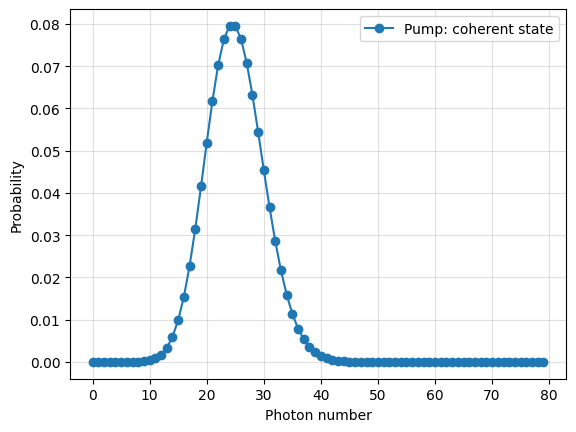

In [5]:
photons = np.arange(n_pump)
if alpha == 0:
    coherent_state = np.zeros(n_pump, dtype=np.complex128)
    coherent_state[0] = 1
else:
    coherent_state = np.exp(-abs(alpha)**2/2 + photons*np.log(complex(alpha))
                            - gammaln(photons+1)/2)
    coherent_state = coherent_state.astype(np.complex128)
    coherent_state /= np.linalg.norm(coherent_state)

vacuum_state = np.zeros(n_signal, dtype=np.complex128)
vacuum_state[0] = 1
common_state = np.kron(coherent_state, vacuum_state)

plt.plot(photons, np.abs(coherent_state)**2, 'o-', label='Pump: coherent state')
plt.xlabel('Photon number')
plt.ylabel('Probability')
plt.grid(alpha=0.4)
plt.legend()
plt.show()

## 6. Sparse-matrix time evolution

In [6]:
start_time = time.time()
linear_solver = splu(evolution_operator_csr.tocsc())

solutions = [common_state]
for i in tqdm(range(steps_number)):
    solutions.append(linear_solver.solve(right_part_operator @ solutions[-1]))

sparse_time = time.time()-start_time
times = np.arange(steps_number+1)*delta_t
print(f'{steps_number} steps completed in {sparse_time:.2f} s')


  0%|          | 0/200 [00:00<?, ?it/s]


 58%|█████▊    | 117/200 [00:00<00:00, 1153.18it/s]


100%|██████████| 200/200 [00:00<00:00, 1103.81it/s]

200 steps completed in 0.20 s


## 7. Photon-number observables and invariant

The number operators in the Fock basis are diagonal, so $\langle N\rangle$ can be obtained directly without constructing a reduced density matrix. We compute

$$\langle N_a\rangle,\quad\langle N_b\rangle,\quad C=2\langle N_a\rangle+\langle N_b\rangle.$$

This is equivalent to the reduced-density-matrix trace in the original notebook but avoids storing large density matrices.


  0%|          | 0/201 [00:00<?, ?it/s]


100%|██████████| 201/201 [00:00<00:00, 14039.22it/s]

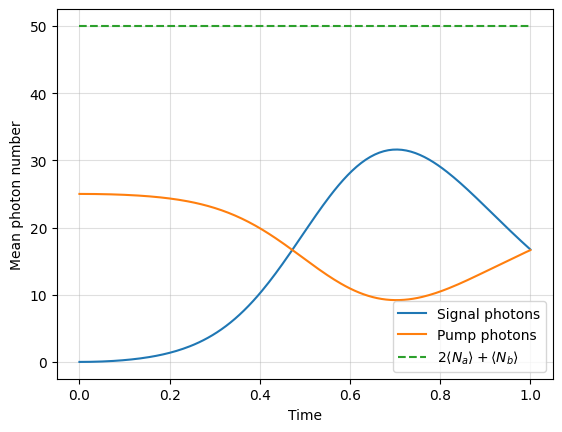

Final invariant drift: -2.842170943040401e-14
Final relative norm: 0.9999999999999947


In [7]:
pump_photons_basis = np.repeat(np.arange(n_pump), n_signal)
signal_photons_basis = np.tile(np.arange(n_signal), n_pump)

pump_photons = []
signal_photons = []
norms = []
for state in tqdm(solutions):
    norm2 = np.vdot(state, state).real
    norms.append(norm2)
    pump_photons.append(np.vdot(state, pump_photons_basis*state).real/norm2)
    signal_photons.append(np.vdot(state, signal_photons_basis*state).real/norm2)

pump_photons = np.array(pump_photons)
signal_photons = np.array(signal_photons)
norms = np.array(norms)
invariant = 2*pump_photons + signal_photons

plt.plot(times, signal_photons, label='Signal photons')
plt.plot(times, pump_photons, label='Pump photons')
plt.plot(times, invariant, '--', label=r'$2\langle N_a\rangle+\langle N_b\rangle$')
plt.xlabel('Time')
plt.ylabel('Mean photon number')
plt.grid(alpha=0.4)
plt.legend()
plt.show()

print('Final invariant drift:', invariant[-1]-invariant[0])
print('Final relative norm:', norms[-1]/norms[0])

## 8. Save the reference and sampled pure states

The saved `.npz` contains the photon-number trajectories, model parameters, and **full sparse state vectors at every tenth time step**. The latter are required for a genuine pure-state fidelity comparison: expectation values alone do not determine fidelity. Regenerate this file after changing any physical or temporal parameters.

In [8]:
reference_path = Path('spdc_sparse_reference_cn_alpha5_T1.npz')
sampled_steps = np.arange(0, len(solutions), 10)
states_sampled = np.stack([solutions[k] for k in sampled_steps])
np.savez_compressed(
    reference_path, times=times,
    pump_photons=pump_photons, signal_photons=signal_photons,
    norms=norms, invariant=invariant,
    states_sampled=states_sampled, sampled_steps=sampled_steps,
    alpha=alpha, chi=chi, t_general=t_general,
    steps_number=steps_number, delta_t=delta_t,
    n_pump=n_pump, n_signal=n_signal,
)
print('Saved:', reference_path, '| sampled states:', states_sampled.shape)

Saved: spdc_sparse_reference_cn_alpha5_T1.npz | sampled states: (21, 12800)


### Fock-basis cutoff checks

The pump coherent state at $\alpha=5$ has mean photon number $25$, so a substantially larger pump cutoff than in the $\alpha=1$ example is required. Here we use `n_pump=80` and `n_signal=160`.

At $T=1$, the upper-edge populations remain negligible (below $10^{-13}$ in the pump and $10^{-17}$ in the signal in a 200-step diagnostic calculation). The signal cutoff is increased to 160 for the longer evolution. The main MPS notebook only loads the saved observables.